In [1]:
# ============================================
# 1. INSTALL REQUIRED LIBRARIES
# ============================================

!pip -q install transformers sentencepiece accelerate nltk tqdm

print("Libraries installed successfully!")

Libraries installed successfully!


In [2]:
# ============================================
# 2. IMPORT LIBRARIES
# ============================================

import os
import re
import string
import random
import time
import gc

import numpy as np
import pandas as pd

import torch

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split

from tqdm.auto import tqdm

from google.colab import files

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

# NLTK resources
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

print("Imports successful!")

Imports successful!


In [3]:
# ============================================
# 3. CHECK GPU
# ============================================

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )

    # Initialize CUDA
    torch.cuda.init()

    # Small GPU test
    a = torch.randn(1000, 1000, device="cuda")
    b = torch.randn(1000, 1000, device="cuda")

    c = a @ b

    torch.cuda.synchronize()

    print("\nGPU test: SUCCESS")

    del a, b, c
    torch.cuda.empty_cache()

else:
    print("\nWARNING: GPU NOT AVAILABLE")
    print("Go to Runtime → Change runtime type → T4 GPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB

GPU test: SUCCESS


In [4]:
# ============================================
# 4. UPLOAD DATASET
# ============================================

print("Upload WELFake_Clean.csv")
print("--------------------------------")

uploaded = files.upload()

print("\nUploaded files:")

for filename in uploaded:
    print(filename)

# Automatically find the CSV
csv_files = [
    f for f in uploaded
    if f.lower().endswith(".csv")
]

if not csv_files:
    raise FileNotFoundError(
        "No CSV file was uploaded."
    )

DATA_PATH = csv_files[0]

print("\nUsing dataset:")
print(DATA_PATH)

Upload WELFake_Clean.csv
--------------------------------


Saving WELFake_Clean.csv to WELFake_Clean.csv

Uploaded files:
WELFake_Clean.csv

Using dataset:
WELFake_Clean.csv


In [6]:
# ============================================
# 5. LOAD DATASET
# ============================================

import sys
import csv

# Increase CSV field limit to handle extremely large text fields
csv.field_size_limit(sys.maxsize)

original_df = pd.read_csv(
    DATA_PATH,
    encoding="utf-8",
    engine="python"
)

print("Dataset loaded successfully!")

print("\nShape:")
print(original_df.shape)

print("\nColumns:")
print(original_df.columns.tolist())

print("\nFirst 5 rows:")
display(original_df.head())

required_columns = {
    "title",
    "text",
    "label"
}

missing = required_columns - set(original_df.columns)

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

print("\nLabel distribution:")
print(
    original_df["label"]
    .value_counts()
    .sort_index()
)

Dataset loaded successfully!

Shape:
(71537, 3)

Columns:
['title', 'text', 'label']

First 5 rows:


,title,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
2,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
3,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1
4,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1



Label distribution:
label
0    35028
1    36509
Name: count, dtype: int64


In [7]:
# ============================================
# 6. DATA CLEANING + PREPROCESSING
# ============================================

stop_words = set(
    stopwords.words("english")
)

lemmatizer = WordNetLemmatizer()


def preprocess_text(text):

    if pd.isna(text):
        return ""

    # Convert to string
    text = str(text)

    # 1. Lowercase
    text = text.lower()

    # 2. Remove URLs
    text = re.sub(
        r"http\S+|www\S+",
        "",
        text
    )

    # 3. Remove HTML tags
    text = re.sub(
        r"<.*?>",
        "",
        text
    )

    # 4. Remove @mentions
    text = re.sub(
        r"@\w+",
        "",
        text
    )

    # 5. Remove hashtags
    text = re.sub(
        r"#\w+",
        "",
        text
    )

    # 6. Remove punctuation
    text = text.translate(
        str.maketrans(
            "",
            "",
            string.punctuation
        )
    )

    # 7. Remove numbers
    text = re.sub(
        r"\d+",
        "",
        text
    )

    # 8. Normalize whitespace
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    # 9. Stopword removal + lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    return " ".join(words)


# Remove missing values
original_df = original_df.dropna(
    subset=["title", "text", "label"]
).copy()

# Remove duplicates
original_df = original_df.drop_duplicates(
    subset=["title", "text", "label"]
).reset_index(drop=True)

print("After cleaning missing/duplicate rows:")
print(original_df.shape)

# Keep raw copies
original_df["title_raw"] = original_df["title"]
original_df["text_raw"] = original_df["text"]

# Clean title
print("\nCleaning titles...")

tqdm.pandas()

original_df["title"] = (
    original_df["title"]
    .progress_apply(preprocess_text)
)

# Clean article text
print("\nCleaning article content...")

original_df["text"] = (
    original_df["text"]
    .progress_apply(preprocess_text)
)

print("\nPreprocessing completed!")

display(
    original_df[
        ["title_raw", "title", "text_raw", "text", "label"]
    ].head()
)

After cleaning missing/duplicate rows:
(63121, 3)

Cleaning titles...


  0%|          | 0/63121 [00:00<?, ?it/s]


Cleaning article content...


  0%|          | 0/63121 [00:00<?, ?it/s]


Preprocessing completed!


,title_raw,title,text_raw,text,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,law enforcement high alert following threat co...,No comment is expected from Barack Obama Membe...,comment expected barack obama member movement ...,1
1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,unbelievable obama’s attorney general say char...,"Now, most of the demonstrators gathered last ...",demonstrator gathered last night exercising co...,1
2,"Bobby Jindal, raised Hindu, uses story of Chri...",bobby jindal raised hindu us story christian c...,A dozen politically active pastors came here f...,dozen politically active pastor came private d...,0
3,SATAN 2: Russia unvelis an image of its terrif...,satan russia unvelis image terrifying new ‘sup...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",r sarmat missile dubbed satan replace s fly mi...,1
4,About Time! Christian Group Sues Amazon and SP...,time christian group sue amazon splc designati...,All we can say on this one is it s about time ...,say one time someone sued southern poverty law...,1


In [8]:
# ============================================
# 7. VERIFY LABELS
# ============================================

print("Label values:")
print(sorted(original_df["label"].unique()))

print("\nLabel counts:")
print(
    original_df["label"]
    .value_counts()
    .sort_index()
)

print("\nLabel percentages:")
print(
    original_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Label values:
[np.int64(0), np.int64(1)]

Label counts:
label
0    34791
1    28330
Name: count, dtype: int64

Label percentages:
label
0    55.12
1    44.88
Name: proportion, dtype: float64


In [9]:
# ============================================
# 8. CREATE INPUT SCENARIOS
# ============================================

# Headline only
headline_df = pd.DataFrame({
    "text": original_df["title"],
    "label": original_df["label"]
})

# Content only
content_df = pd.DataFrame({
    "text": original_df["text"],
    "label": original_df["label"]
})

# Headline + content
combined_df = pd.DataFrame({
    "text":
        original_df["title"]
        + " "
        + original_df["text"],
    "label": original_df["label"]
})

print("Headline dataset:", headline_df.shape)
print("Content dataset:", content_df.shape)
print("Combined dataset:", combined_df.shape)

Headline dataset: (63121, 2)
Content dataset: (63121, 2)
Combined dataset: (63121, 2)


In [10]:
# ============================================
# 9. SAVE CLEAN DATASETS
# ============================================

headline_df.to_csv(
    "/content/Headline_Only.csv",
    index=False
)

content_df.to_csv(
    "/content/Content_Only.csv",
    index=False
)

combined_df.to_csv(
    "/content/Headline_Content.csv",
    index=False
)

print("Clean datasets saved successfully!")

Clean datasets saved successfully!


In [11]:
# ============================================
# 10. STRATIFIED 60/20/20 SPLIT
# ============================================

SEED = 42

# --------------------------------------------
# Combined headline + content
# --------------------------------------------

X_combined = combined_df["text"]
y_combined = combined_df["label"]

# First: 80% temporary + 20% test
X_temp_comb, X_test_comb, y_temp_comb, y_test_comb = train_test_split(
    X_combined,
    y_combined,
    test_size=0.20,
    stratify=y_combined,
    random_state=SEED
)

# Then: 75% of remaining 80% = 60% total
X_train_comb, X_val_comb, y_train_comb, y_val_comb = train_test_split(
    X_temp_comb,
    y_temp_comb,
    test_size=0.25,
    stratify=y_temp_comb,
    random_state=SEED
)

print("============================================")
print("COMBINED INPUT SPLIT")
print("============================================")

print("Dataset     :", len(combined_df))
print("Training    :", len(X_train_comb))
print("Validation  :", len(X_val_comb))
print("Test        :", len(X_test_comb))

print("\nExpected approximately:")
print("Train      ≈ 60%")
print("Validation ≈ 20%")
print("Test       ≈ 20%")

COMBINED INPUT SPLIT
Dataset     : 63121
Training    : 37872
Validation  : 12624
Test        : 12625

Expected approximately:
Train      ≈ 60%
Validation ≈ 20%
Test       ≈ 20%


In [12]:
# ============================================
# 11. VERIFY STRATIFICATION
# ============================================

print("TRAIN LABEL DISTRIBUTION")
print(
    y_train_comb.value_counts(normalize=True)
    .sort_index()
)

print("\nVALIDATION LABEL DISTRIBUTION")
print(
    y_val_comb.value_counts(normalize=True)
    .sort_index()
)

print("\nTEST LABEL DISTRIBUTION")
print(
    y_test_comb.value_counts(normalize=True)
    .sort_index()
)

TRAIN LABEL DISTRIBUTION
label
0    0.551172
1    0.448828
Name: proportion, dtype: float64

VALIDATION LABEL DISTRIBUTION
label
0    0.551172
1    0.448828
Name: proportion, dtype: float64

TEST LABEL DISTRIBUTION
label
0    0.551208
1    0.448792
Name: proportion, dtype: float64


In [13]:
# ============================================
# 12. DATA VALIDATION
# ============================================

print("Missing values")
print("----------------")

print(
    "Train:",
    X_train_comb.isna().sum()
)

print(
    "Validation:",
    X_val_comb.isna().sum()
)

print(
    "Test:",
    X_test_comb.isna().sum()
)

print("\nEmpty texts")

print(
    "Train:",
    (X_train_comb.str.strip() == "").sum()
)

print(
    "Validation:",
    (X_val_comb.str.strip() == "").sum()
)

print(
    "Test:",
    (X_test_comb.str.strip() == "").sum()
)

print("\nExample training article:")
print(
    X_train_comb.iloc[0][:1000]
)

Missing values
----------------
Train: 0
Validation: 0
Test: 0

Empty texts
Train: 5
Validation: 0
Test: 0

Example training article:
jeb bush endorsed former rival lindsey graham key state charleston scwashington reuters republican candidate jeb bush endorsed former rival senator lindsey graham south carolina friday winning important ally state feb vote could prove critical race presidential nominee move hawkish graham ended presidential campaign dec reflected view bush offered best plan defeat islamic state militant forming alliance muslim nation region graham’s decision could significant swaying south carolina republican voter also good friend senator john mccain republican presidential nominee remains influential figure party spoken warmly bush recent month graham said vote south carolina follow iowa’s caucus feb new hampshire’s primary feb reset race “jeb bush going nominee win election party can’t afford lose president reset world bring u together solve hard problems” graham said

In [14]:
# ============================================
# 13. REPRODUCIBILITY
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seeds configured:", SEED)

Random seeds configured: 42


In [15]:
# ============================================
# 14. FINAL GPU CHECK BEFORE ALBERT
# ============================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

if device.type == "cuda":

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    torch.cuda.empty_cache()

    print(
        "Allocated:",
        round(
            torch.cuda.memory_allocated() / 1024**3,
            2
        ),
        "GB"
    )

    print(
        "Reserved:",
        round(
            torch.cuda.memory_reserved() / 1024**3,
            2
        ),
        "GB"
    )

else:
    print(
        "WARNING: ALBERT will run on CPU."
    )

Device: cuda
GPU: Tesla T4
Allocated: 0.01 GB
Reserved: 0.02 GB


In [16]:

# ============================================
# Prepare ALBERT - Headline + Content
# ============================================

def prepare_albert_text(X):
    # Retrieve the original rows using the existing split indices
    titles = (
        original_df.loc[X.index, "title"]
        .fillna("")
        .astype(str)
        .str.strip()
        .reset_index(drop=True)
    )

    contents = (
        original_df.loc[X.index, "text"]
        .fillna("")
        .astype(str)
        .str.strip()
        .reset_index(drop=True)
    )

    # Combine headline and article content
    combined = (titles + " " + contents).str.strip()

    return combined.tolist()


# Prepare text for each existing split
X_train_albert = prepare_albert_text(X_train_comb)
X_val_albert = prepare_albert_text(X_val_comb)
X_test_albert = prepare_albert_text(X_test_comb)

# Preserve the corresponding labels in the same row order
y_train_albert = (
    y_train_comb.reindex(X_train_comb.index).astype(int).to_numpy()
)
y_val_albert = (
    y_val_comb.reindex(X_val_comb.index).astype(int).to_numpy()
)
y_test_albert = (
    y_test_comb.reindex(X_test_comb.index).astype(int).to_numpy()
)

# Verify the prepared data
print("ALBERT INPUT DATA")
print("-----------------")
print("Training samples:", len(X_train_albert))
print("Validation samples:", len(X_val_albert))
print("Test samples:", len(X_test_albert))

print("\nLabel array shapes:")
print("Train:", y_train_albert.shape)
print("Validation:", y_val_albert.shape)
print("Test:", y_test_albert.shape)

print("\nEmpty text samples:")
print("Train:", sum(not text for text in X_train_albert))
print("Validation:", sum(not text for text in X_val_albert))
print("Test:", sum(not text for text in X_test_albert))

print("\nExample combined text:")
print(X_train_albert[0][:500])

print("\nData preparation completed.")


ALBERT INPUT DATA
-----------------
Training samples: 37872
Validation samples: 12624
Test samples: 12625

Label array shapes:
Train: (37872,)
Validation: (12624,)
Test: (12625,)

Empty text samples:
Train: 5
Validation: 0
Test: 0

Example combined text:
jeb bush endorsed former rival lindsey graham key state charleston scwashington reuters republican candidate jeb bush endorsed former rival senator lindsey graham south carolina friday winning important ally state feb vote could prove critical race presidential nominee move hawkish graham ended presidential campaign dec reflected view bush offered best plan defeat islamic state militant forming alliance muslim nation region graham’s decision could significant swaying south carolina republican vo

Data preparation completed.


In [17]:

from transformers import AutoTokenizer

# Load the pretrained ALBERT tokenizer
MODEL_NAME = "albert-base-v2"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully!")
print("Model:", MODEL_NAME)
print("Vocabulary size:", tokenizer.vocab_size)
print("Maximum model input length:", tokenizer.model_max_length)

# Test tokenization on one combined news article
sample_text = X_train_albert[0]

sample_tokens = tokenizer(
    sample_text,
    truncation=True,
    max_length=200
)

print("\nOriginal text:")
print(sample_text[:300])

print("\nToken IDs:")
print(sample_tokens["input_ids"][:30])

print("\nTokens:")
print(tokenizer.convert_ids_to_tokens(
    sample_tokens["input_ids"][:30]
))


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

Tokenizer loaded successfully!
Model: albert-base-v2
Vocabulary size: 30000
Maximum model input length: 512

Original text:
jeb bush endorsed former rival lindsey graham key state charleston scwashington reuters republican candidate jeb bush endorsed former rival senator lindsey graham south carolina friday winning important ally state feb vote could prove critical race presidential nominee move hawkish graham ended pres

Token IDs:
[2, 25301, 3382, 12943, 336, 4989, 20824, 4497, 1246, 146, 11565, 4729, 26580, 27853, 2235, 2316, 25301, 3382, 12943, 336, 4989, 3600, 20824, 4497, 180, 2016, 4619, 1414, 681, 13]

Tokens:
['[CLS]', '▁jeb', '▁bush', '▁endorsed', '▁former', '▁rival', '▁lindsey', '▁graham', '▁key', '▁state', '▁charleston', '▁sc', 'washington', '▁reuters', '▁republican', '▁candidate', '▁jeb', '▁bush', '▁endorsed', '▁former', '▁rival', '▁senator', '▁lindsey', '▁graham', '▁south', '▁carolina', '▁friday', '▁winning', '▁important', '▁']


In [18]:

# ============================================
# Tokenize ALBERT inputs
# ============================================

MAX_LENGTH = 200

def tokenize_texts(texts, split_name, batch_size=1000):
    input_ids_chunks = []
    attention_mask_chunks = []

    print(f"Tokenizing {split_name}: {len(texts)} samples")

    for start in range(0, len(texts), batch_size):
        batch_texts = texts[start:start + batch_size]

        encoded = tokenizer(
            batch_texts,
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids_chunks.append(encoded["input_ids"])
        attention_mask_chunks.append(encoded["attention_mask"])

    input_ids = torch.cat(input_ids_chunks, dim=0)
    attention_mask = torch.cat(attention_mask_chunks, dim=0)

    print("Input IDs shape:", tuple(input_ids.shape))
    print("Attention masks shape:", tuple(attention_mask.shape))

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask
    }


train_encodings = tokenize_texts(
    X_train_albert, "Training"
)

val_encodings = tokenize_texts(
    X_val_albert, "Validation"
)

test_encodings = tokenize_texts(
    X_test_albert, "Test"
)

print("\nTokenization completed successfully.")


Tokenizing Training: 37872 samples
Input IDs shape: (37872, 200)
Attention masks shape: (37872, 200)
Tokenizing Validation: 12624 samples
Input IDs shape: (12624, 200)
Attention masks shape: (12624, 200)
Tokenizing Test: 12625 samples
Input IDs shape: (12625, 200)
Attention masks shape: (12625, 200)

Tokenization completed successfully.


In [19]:

from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Convert labels to PyTorch tensors
y_train_tensor = torch.tensor(y_train_albert, dtype=torch.long)
y_val_tensor = torch.tensor(y_val_albert, dtype=torch.long)
y_test_tensor = torch.tensor(y_test_albert, dtype=torch.long)

# Create datasets
train_dataset = TensorDataset(
    train_encodings["input_ids"],
    train_encodings["attention_mask"],
    y_train_tensor
)

val_dataset = TensorDataset(
    val_encodings["input_ids"],
    val_encodings["attention_mask"],
    y_val_tensor
)

test_dataset = TensorDataset(
    test_encodings["input_ids"],
    test_encodings["attention_mask"],
    y_test_tensor
)

# Batch size for GPU training
BATCH_SIZE = 16

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("PyTorch datasets and DataLoaders created!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Inspect one training batch
input_ids, attention_mask, labels = next(iter(train_loader))

print("\nOne training batch:")
print("Input IDs:", input_ids.shape)
print("Attention mask:", attention_mask.shape)
print("Labels:", labels.shape)
print("Label values:", torch.unique(labels).tolist())


PyTorch datasets and DataLoaders created!
Training batches: 2367
Validation batches: 789
Test batches: 790

One training batch:
Input IDs: torch.Size([16, 200])
Attention mask: torch.Size([16, 200])
Labels: torch.Size([16])
Label values: [0, 1]


In [20]:

from transformers import AutoModelForSequenceClassification
import torch

# Select GPU when available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained ALBERT with a two-class output layer
model_albert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# Move the model to the selected device
model_albert = model_albert.to(device)

print("ALBERT model loaded successfully!")
print("Checkpoint:", MODEL_NAME)
print("Device:", device)
print("Number of output classes:", model_albert.config.num_labels)

# Count model parameters
total_params = sum(
    p.numel() for p in model_albert.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model_albert.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# Check GPU memory
if torch.cuda.is_available():
    print(
        f"GPU memory allocated: "
        f"{torch.cuda.memory_allocated() / (1024**3):.2f} GB"
    )


model.safetensors: reconstructing file:   0%|          |  0.00B / 47.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: albert-base-v2
Key                          | Status     | 
-----------------------------+------------+-
predictions.decoder.bias     | UNEXPECTED | 
predictions.bias             | UNEXPECTED | 
predictions.dense.bias       | UNEXPECTED | 
predictions.LayerNorm.bias   | UNEXPECTED | 
predictions.LayerNorm.weight | UNEXPECTED | 
predictions.dense.weight     | UNEXPECTED | 
classifier.bias              | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ALBERT model loaded successfully!
Checkpoint: albert-base-v2
Device: cuda
Number of output classes: 2
Total parameters: 11,685,122
Trainable parameters: 11,685,122
GPU memory allocated: 0.05 GB


In [22]:

from transformers import get_linear_schedule_with_warmup

# ============================================
# ALBERT training configuration
# ============================================

LEARNING_RATE = 2e-5
EPOCHS = 5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model_albert.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Calculate total training steps
total_training_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_training_steps * WARMUP_RATIO)

# Linear learning-rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

print("ALBERT training configuration")
print("-----------------------------")
print("Learning rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)
print("Weight decay:", WEIGHT_DECAY)
print("Batch size:", BATCH_SIZE)
print("Maximum sequence length:", MAX_LENGTH)
print("Warmup steps:", warmup_steps)
print("Total training steps:", total_training_steps)
print(
    "Model dropout:",
    model_albert.config.hidden_dropout_prob
)
print("Device:", device)


ALBERT training configuration
-----------------------------
Learning rate: 2e-05
Epochs: 5
Weight decay: 0.01
Batch size: 16
Maximum sequence length: 200
Warmup steps: 1183
Total training steps: 11835
Model dropout: 0
Device: cuda


In [23]:

print("Hidden dropout:",
      model_albert.config.hidden_dropout_prob)

print("Attention dropout:",
      model_albert.config.attention_probs_dropout_prob)

print("Classifier dropout:",
      getattr(model_albert.config, "classifier_dropout_prob", "Not specified"))

if hasattr(model_albert, "dropout"):
    print("Actual classifier dropout layer:",
          model_albert.dropout.p)

Hidden dropout: 0
Attention dropout: 0
Classifier dropout: 0.1
Actual classifier dropout layer: 0.1


In [24]:

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

try:
    # Initialize the CUDA context
    torch.cuda.init()

    # Test a small matrix multiplication on the GPU
    a = torch.randn(16, 200, device="cuda")
    b = torch.randn(200, 128, device="cuda")
    c = a @ b

    torch.cuda.synchronize()

    print("\nGPU matrix multiplication: SUCCESS")
    print("Output shape:", tuple(c.shape))
    print("GPU:", torch.cuda.get_device_name(0))

except Exception as e:
    print("\nGPU matrix multiplication: FAILED")
    print(type(e).__name__, str(e))


PyTorch: 2.11.0+cu130
CUDA available: True

GPU matrix multiplication: SUCCESS
Output shape: (16, 128)
GPU: Tesla T4


In [25]:
# Load model, tokenizer, data loaders, and retry ALBERT forward pass
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# 1. Define model metadata
MODEL_NAME = "albert-base-v2"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Re-initialize tokenizer and model on device
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model_albert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)
model_albert = model_albert.to(device)

# 3. Safe GPU cache clearing (only if CUDA is available)
if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

model_albert.eval()

# Note: This requires 'train_loader' to be defined in your runtime.
# If train_loader is not defined, please execute your data loading cells first.
try:
    batch = next(iter(train_loader))
    input_ids, attention_mask, labels = [
        tensor.to(device) for tensor in batch
    ]

    with torch.no_grad():
        outputs = model_albert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

    if device.type == "cuda":
        torch.cuda.synchronize()

    print("Forward pass successful!")
    print("Logits shape:", tuple(outputs.logits.shape))
    print("Loss:", round(outputs.loss.item(), 4))
    print("Predicted classes:", outputs.logits.argmax(dim=1).tolist()[:10])
    print("Actual classes:", labels.tolist()[:10])

except NameError as e:
    print("NameError:", e)
    print("Please run the previous cells to define 'train_loader' before running this pass.")

# Prepare the model for training
model_albert.train()

Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

[transformers] AlbertForSequenceClassification LOAD REPORT from: albert-base-v2
Key                          | Status     | 
-----------------------------+------------+-
predictions.decoder.bias     | UNEXPECTED | 
predictions.bias             | UNEXPECTED | 
predictions.dense.bias       | UNEXPECTED | 
predictions.LayerNorm.bias   | UNEXPECTED | 
predictions.LayerNorm.weight | UNEXPECTED | 
predictions.dense.weight     | UNEXPECTED | 
classifier.bias              | MISSING    | 
classifier.weight            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Forward pass successful!
Logits shape: (16, 2)
Loss: 0.7519
Predicted classes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 0]
Actual classes: [1, 0, 1, 0, 1, 0, 0, 1, 1, 1]


AlbertForSequenceClassification(
  (albert): AlbertModel(
    (embeddings): AlbertEmbeddings(
      (word_embeddings): Embedding(30000, 128, padding_idx=0)
      (position_embeddings): Embedding(512, 128)
      (token_type_embeddings): Embedding(2, 128)
      (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0, inplace=False)
    )
    (encoder): AlbertTransformer(
      (embedding_hidden_mapping_in): Linear(in_features=128, out_features=768, bias=True)
      (albert_layer_groups): ModuleList(
        (0): AlbertLayerGroup(
          (albert_layers): ModuleList(
            (0): AlbertLayer(
              (full_layer_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
              (attention): AlbertAttention(
                (attention_dropout): Dropout(p=0, inplace=False)
                (output_dropout): Dropout(p=0, inplace=False)
                (query): Linear(in_features=768, out_features=768, bias=True)
               

In [26]:

# Check which ALBERT pipeline variables still exist

required_variables = [
    "tokenizer",
    "X_train_albert",
    "X_val_albert",
    "X_test_albert",
    "y_train_albert",
    "y_val_albert",
    "y_test_albert",
    "train_encodings",
    "val_encodings",
    "test_encodings",
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_loader",
    "val_loader",
    "test_loader",
    "model_albert",
    "optimizer",
    "scheduler"
]

for name in required_variables:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: AVAILABLE ({type(obj).__name__})")
    else:
        print(f"{name}: MISSING")

print("\nCUDA available:", torch.cuda.is_available())


tokenizer: AVAILABLE (AlbertTokenizer)
X_train_albert: AVAILABLE (list)
X_val_albert: AVAILABLE (list)
X_test_albert: AVAILABLE (list)
y_train_albert: AVAILABLE (ndarray)
y_val_albert: AVAILABLE (ndarray)
y_test_albert: AVAILABLE (ndarray)
train_encodings: AVAILABLE (dict)
val_encodings: AVAILABLE (dict)
test_encodings: AVAILABLE (dict)
train_dataset: AVAILABLE (TensorDataset)
val_dataset: AVAILABLE (TensorDataset)
test_dataset: AVAILABLE (TensorDataset)
train_loader: AVAILABLE (DataLoader)
val_loader: AVAILABLE (DataLoader)
test_loader: AVAILABLE (DataLoader)
model_albert: AVAILABLE (AlbertForSequenceClassification)
optimizer: AVAILABLE (AdamW)
scheduler: AVAILABLE (LambdaLR)

CUDA available: True


In [27]:

import pandas as pd
import numpy as np
import torch

# Check the original dataset and split variables still exist
required = [
    "original_df",
    "X_train_comb", "X_val_comb", "X_test_comb",
    "y_train_comb", "y_val_comb", "y_test_comb"
]

missing = [name for name in required if name not in globals()]

if missing:
    print("Missing prerequisite variables:", missing)
    print("Stop here and send me this output.")
else:
    def prepare_albert_text(X):
        titles = (
            original_df.loc[X.index, "title"]
            .fillna("")
            .astype(str)
            .str.strip()
            .reset_index(drop=True)
        )

        contents = (
            original_df.loc[X.index, "text"]
            .fillna("")
            .astype(str)
            .str.strip()
            .reset_index(drop=True)
        )

        return (titles + " " + contents).str.strip().tolist()

    # Restore the combined original text
    X_train_albert = prepare_albert_text(X_train_comb)
    X_val_albert = prepare_albert_text(X_val_comb)
    X_test_albert = prepare_albert_text(X_test_comb)

    # Restore labels in matching row order
    y_train_albert = (
        y_train_comb.reindex(X_train_comb.index)
        .astype(int).to_numpy()
    )
    y_val_albert = (
        y_val_comb.reindex(X_val_comb.index)
        .astype(int).to_numpy()
    )
    y_test_albert = (
        y_test_comb.reindex(X_test_comb.index)
        .astype(int).to_numpy()
    )

    print("Text and labels restored successfully!")
    print("Train:", len(X_train_albert), y_train_albert.shape)
    print("Validation:", len(X_val_albert), y_val_albert.shape)
    print("Test:", len(X_test_albert), y_test_albert.shape)
    print("\nSample:", X_train_albert[0][:200])


Text and labels restored successfully!
Train: 37872 (37872,)
Validation: 12624 (12624,)
Test: 12625 (12625,)

Sample: jeb bush endorsed former rival lindsey graham key state charleston scwashington reuters republican candidate jeb bush endorsed former rival senator lindsey graham south carolina friday winning importa


In [28]:
print("=== DATASET / SPLIT STATE ===")

names_to_check = [
    "df",
    "data",
    "dataset",
    "clean_df",
    "clean_title",
    "clean_text",
    "X_train",
    "X_val",
    "X_test",
    "y_train",
    "y_val",
    "y_test",
    "X_train_comb",
    "X_val_comb",
    "X_test_comb",
    "y_train_comb",
    "y_val_comb",
    "y_test_comb",
]

for name in names_to_check:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}: EXISTS")
        print("  Type:", type(obj).__name__)

        if hasattr(obj, "shape"):
            print("  Shape:", obj.shape)

        if isinstance(obj, pd.DataFrame):
            print("  Columns:", obj.columns.tolist())

    else:
        print(f"{name}: MISSING")

=== DATASET / SPLIT STATE ===
df: MISSING
data: MISSING
dataset: MISSING
clean_df: MISSING
clean_title: MISSING
clean_text: MISSING
X_train: MISSING
X_val: MISSING
X_test: MISSING
y_train: MISSING
y_val: MISSING
y_test: MISSING

X_train_comb: EXISTS
  Type: Series
  Shape: (37872,)

X_val_comb: EXISTS
  Type: Series
  Shape: (12624,)

X_test_comb: EXISTS
  Type: Series
  Shape: (12625,)

y_train_comb: EXISTS
  Type: Series
  Shape: (37872,)

y_val_comb: EXISTS
  Type: Series
  Shape: (12624,)

y_test_comb: EXISTS
  Type: Series
  Shape: (12625,)


In [29]:
# ============================================
# RECOVER ALBERT INPUT PIPELINE
# ============================================

import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

MAX_LENGTH = 200
BATCH_SIZE = 16

# Tokenize text in batches to avoid excessive memory usage
def tokenize_for_albert(texts, name, batch_size=1000):
    input_ids_parts = []
    attention_mask_parts = []

    print(f"Tokenizing {name}: {len(texts)} samples")

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        encoded = tokenizer(
            batch,
            max_length=MAX_LENGTH,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids_parts.append(encoded["input_ids"])
        attention_mask_parts.append(encoded["attention_mask"])

    input_ids = torch.cat(input_ids_parts, dim=0)
    attention_mask = torch.cat(attention_mask_parts, dim=0)

    print("  Input IDs:", tuple(input_ids.shape))
    print("  Attention:", tuple(attention_mask.shape))

    return input_ids, attention_mask


# Tokenize current verified splits
train_input_ids, train_attention_mask = tokenize_for_albert(
    X_train_comb.tolist(), "Training"
)

val_input_ids, val_attention_mask = tokenize_for_albert(
    X_val_comb.tolist(), "Validation"
)

test_input_ids, test_attention_mask = tokenize_for_albert(
    X_test_comb.tolist(), "Test"
)


# Convert labels to tensors
train_labels = torch.tensor(
    y_train_comb.to_numpy(),
    dtype=torch.long
)

val_labels = torch.tensor(
    y_val_comb.to_numpy(),
    dtype=torch.long
)

test_labels = torch.tensor(
    y_test_comb.to_numpy(),
    dtype=torch.long
)


# Create datasets
train_dataset = TensorDataset(
    train_input_ids,
    train_attention_mask,
    train_labels
)

val_dataset = TensorDataset(
    val_input_ids,
    val_attention_mask,
    val_labels
)

test_dataset = TensorDataset(
    test_input_ids,
    test_attention_mask,
    test_labels
)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)


print("\n=== ALBERT PIPELINE RESTORED ===")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
batch = next(iter(train_loader))

print("\nOne training batch:")
print("Input IDs:", tuple(batch[0].shape))
print("Attention mask:", tuple(batch[1].shape))
print("Labels:", tuple(batch[2].shape))
print("Labels present:", torch.unique(batch[2]).tolist())

Tokenizing Training: 37872 samples
  Input IDs: (37872, 200)
  Attention: (37872, 200)
Tokenizing Validation: 12624 samples
  Input IDs: (12624, 200)
  Attention: (12624, 200)
Tokenizing Test: 12625 samples
  Input IDs: (12625, 200)
  Attention: (12625, 200)

=== ALBERT PIPELINE RESTORED ===
Training samples: 37872
Validation samples: 12624
Test samples: 12625

Training batches: 2367
Validation batches: 789
Test batches: 790

One training batch:
Input IDs: (16, 200)
Attention mask: (16, 200)
Labels: (16,)
Labels present: [0, 1]


In [30]:
# ============================================
# ALBERT FORWARD-PASS TEST
# ============================================

import torch

# Safe CUDA context and cache operations
if device.type == "cuda":
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

model_albert.eval()

# Get one batch
input_ids, attention_mask, labels = next(iter(train_loader))

# Move batch to the selected device
input_ids = input_ids.to(device)
attention_mask = attention_mask.to(device)
labels = labels.to(device)

# Forward pass
with torch.no_grad():
    outputs = model_albert(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

if device.type == "cuda":
    torch.cuda.synchronize()

print("Forward pass successful!")
print("Logits shape:", tuple(outputs.logits.shape))
print("Loss:", round(outputs.loss.item(), 4))

print("\nFirst 10 predictions:")
print(outputs.logits.argmax(dim=1)[:10].cpu().tolist())

print("\nFirst 10 actual labels:")
print(labels[:10].cpu().tolist())

# Put model back into training mode
model_albert.train()

Forward pass successful!
Logits shape: (16, 2)
Loss: 0.8449

First 10 predictions:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

First 10 actual labels:
[0, 0, 0, 0, 1, 0, 1, 0, 0, 0]


AlbertForSequenceClassification(
  (albert): AlbertModel(
    (embeddings): AlbertEmbeddings(
      (word_embeddings): Embedding(30000, 128, padding_idx=0)
      (position_embeddings): Embedding(512, 128)
      (token_type_embeddings): Embedding(2, 128)
      (LayerNorm): LayerNorm((128,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0, inplace=False)
    )
    (encoder): AlbertTransformer(
      (embedding_hidden_mapping_in): Linear(in_features=128, out_features=768, bias=True)
      (albert_layer_groups): ModuleList(
        (0): AlbertLayerGroup(
          (albert_layers): ModuleList(
            (0): AlbertLayer(
              (full_layer_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
              (attention): AlbertAttention(
                (attention_dropout): Dropout(p=0, inplace=False)
                (output_dropout): Dropout(p=0, inplace=False)
                (query): Linear(in_features=768, out_features=768, bias=True)
               

In [31]:
# ============================================
# ALBERT OPTIMIZER + LEARNING RATE SCHEDULER
# ============================================

from transformers import get_linear_schedule_with_warmup

LEARNING_RATE = 2e-5
EPOCHS = 5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10

# Optimizer
optimizer = torch.optim.AdamW(
    model_albert.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Total number of optimization steps
total_steps = len(train_loader) * EPOCHS

# Warmup steps
warmup_steps = int(total_steps * WARMUP_RATIO)

# Linear learning-rate scheduler
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Optimizer and scheduler ready")
print("--------------------------------")
print("Learning rate :", LEARNING_RATE)
print("Epochs        :", EPOCHS)
print("Weight decay  :", WEIGHT_DECAY)
print("Batch size    :", BATCH_SIZE)
print("Sequence len  :", MAX_LENGTH)
print("Total steps   :", total_steps)
print("Warmup steps  :", warmup_steps)

Optimizer and scheduler ready
--------------------------------
Learning rate : 2e-05
Epochs        : 5
Weight decay  : 0.01
Batch size    : 16
Sequence len  : 200
Total steps   : 11835
Warmup steps  : 1183


In [32]:
# ============================================
# TRAIN ALBERT - HEADLINE + CONTENT
# ============================================

import time
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

# Mixed precision for the T4 GPU
use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

best_val_f1 = -1.0
best_epoch = 0

train_history = []
val_history = []

print("Starting ALBERT training...")
print("=" * 50)

for epoch in range(EPOCHS):

    epoch_start = time.time()

    # ----------------------------
    # TRAINING
    # ----------------------------
    model_albert.train()

    total_train_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} - Training"
    )

    for input_ids, attention_mask, labels in train_bar:

        input_ids = input_ids.to(device, non_blocking=True)
        attention_mask = attention_mask.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Mixed precision forward pass
        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = model_albert(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        # Backpropagation
        scaler.scale(loss).backward()

        # Gradient clipping
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model_albert.parameters(),
            max_norm=1.0
        )

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_train_loss += loss.item()

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = total_train_loss / len(train_loader)

    # ----------------------------
    # VALIDATION
    # ----------------------------
    model_albert.eval()

    total_val_loss = 0.0
    val_predictions = []
    val_true_labels = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{EPOCHS} - Validation"
        )

        for input_ids, attention_mask, labels in val_bar:

            input_ids = input_ids.to(
                device,
                non_blocking=True
            )

            attention_mask = attention_mask.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = model_albert(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_val_loss += outputs.loss.item()

            predictions = outputs.logits.argmax(
                dim=1
            )

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_true_labels.extend(
                labels.cpu().numpy()
            )

    avg_val_loss = total_val_loss / len(val_loader)

    val_f1 = f1_score(
        val_true_labels,
        val_predictions,
        average="weighted",
        zero_division=0
    )

    epoch_time = time.time() - epoch_start

    train_history.append(avg_train_loss)
    val_history.append(avg_val_loss)

    print("\n" + "=" * 50)
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss     : {avg_train_loss:.4f}")
    print(f"Validation Loss: {avg_val_loss:.4f}")
    print(f"Validation F1  : {val_f1:.4f}")
    print(f"Epoch Time     : {epoch_time:.2f} sec")

    # ----------------------------
    # SAVE BEST MODEL
    # ----------------------------
    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": model_albert.state_dict(),
                "val_f1": best_val_f1
            },
            "albert_combined_best.pt"
        )

        print("*** New best model saved ***")

    print("=" * 50)

print("\nTraining completed!")
print(f"Best epoch: {best_epoch}")
print(f"Best validation weighted F1: {best_val_f1:.4f}")

Starting ALBERT training...


Epoch 1/5 - Training:   0%|          | 0/2367 [00:00<?, ?it/s]

Epoch 1/5 - Validation:   0%|          | 0/789 [00:00<?, ?it/s]


Epoch 1/5
Train Loss     : 0.1826
Validation Loss: 0.0934
Validation F1  : 0.9781
Epoch Time     : 567.26 sec
*** New best model saved ***


Epoch 2/5 - Training:   0%|          | 0/2367 [00:00<?, ?it/s]

...

Epoch 4/5 - Validation:   0%|          | 0/789 [00:00<?, ?it/s]


Epoch 4/5
Train Loss     : 0.0190
Validation Loss: 0.0843
Validation F1  : 0.9864
Epoch Time     : 560.04 sec
*** New best model saved ***


Epoch 5/5 - Training:   0%|          | 0/2367 [00:00<?, ?it/s]

Epoch 5/5 - Validation:   0%|          | 0/789 [00:00<?, ?it/s]


Epoch 5/5
Train Loss     : 0.0064
Validation Loss: 0.1009
Validation F1  : 0.9861
Epoch Time     : 558.62 sec

Training completed!
Best epoch: 4
Best validation weighted F1: 0.9864


In [33]:
# ============================================
# FINAL ALBERT TEST EVALUATION
# ============================================

import torch
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Load the best validation checkpoint
checkpoint = torch.load(
    "albert_combined_best.pt",
    map_location=device
)

model_albert.load_state_dict(
    checkpoint["model_state_dict"]
)

model_albert.eval()

all_probs = []
all_preds = []
all_labels = []

test_start = time.time()

with torch.no_grad():

    for input_ids, attention_mask, labels in test_loader:

        input_ids = input_ids.to(
            device,
            non_blocking=True
        )

        attention_mask = attention_mask.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            outputs = model_albert(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

        # Convert logits to probabilities
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )[:, 1]

        predictions = (
            outputs.logits.argmax(dim=1)
        )

        all_probs.extend(
            probabilities.cpu().numpy()
        )

        all_preds.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

test_time = time.time() - test_start

# ----------------------------
# Metrics
# ----------------------------

accuracy_albert = accuracy_score(
    all_labels,
    all_preds
)

precision_albert = precision_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

recall_albert = recall_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

f1_albert = f1_score(
    all_labels,
    all_preds,
    average="macro",
    zero_division=0
)

auc_albert = roc_auc_score(
    all_labels,
    all_probs
)

print("\n======================================")
print("ALBERT - HEADLINE + CONTENT")
print("FINAL TEST RESULTS")
print("======================================")

print(f"Accuracy  : {accuracy_albert:.4f}")
print(f"Precision : {precision_albert:.4f}")
print(f"Recall    : {recall_albert:.4f}")
print(f"F1-score  : {f1_albert:.4f}")
print(f"ROC-AUC   : {auc_albert:.4f}")

print(f"\nBest epoch: {checkpoint['epoch']}")
print(
    f"Best validation weighted F1: "
    f"{checkpoint['val_f1']:.4f}"
)

print(f"Test inference time: {test_time:.2f} sec")

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_preds,
        zero_division=0
    )
)


ALBERT - HEADLINE + CONTENT
FINAL TEST RESULTS
Accuracy  : 0.9863
Precision : 0.9863
Recall    : 0.9860
F1-score  : 0.9861
ROC-AUC   : 0.9980

Best epoch: 4
Best validation weighted F1: 0.9864
Test inference time: 58.74 sec

Confusion Matrix:
[[6884   75]
 [  98 5568]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6959
           1       0.99      0.98      0.98      5666

    accuracy                           0.99     12625
   macro avg       0.99      0.99      0.99     12625
weighted avg       0.99      0.99      0.99     12625



In [34]:
# ============================================
# 31. INSTALL / IMPORT EXPLAINABILITY TOOLS
# ============================================

!pip -q install captum

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from captum.attr import LayerIntegratedGradients

# Make sure we are using the final trained model
model_albert.eval()

print("Captum ready!")
print("Device:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 28.1 MB/s eta 0:00:00
Captum ready!
Device: cuda


In [35]:
# ============================================
# 32. CHOOSE A TEST EXAMPLE TO EXPLAIN
# ============================================

# Use the already-computed final test predictions.
all_labels_np = np.asarray(all_labels).astype(int)
all_preds_np = np.asarray(all_preds).astype(int)
all_probs_np = np.asarray(all_probs).astype(float)

# Prefer a correctly classified fake example.
fake_correct = np.where(
    (all_labels_np == 1) & (all_preds_np == 1)
)[0]

# Fall back to the first test sample if necessary.
if len(fake_correct) > 0:
    EXPLAIN_INDEX = int(fake_correct[0])
else:
    EXPLAIN_INDEX = 0

print("Test index:", EXPLAIN_INDEX)
print("Actual label:", all_labels_np[EXPLAIN_INDEX], "(1=fake, 0=real)")
print("Predicted label:", all_preds_np[EXPLAIN_INDEX])
print("Fake probability:", round(all_probs_np[EXPLAIN_INDEX], 4))

# Original combined text for this exact test row
example_text = X_test_comb.iloc[EXPLAIN_INDEX]

print("\nTEXT BEING EXPLAINED:\n")
print(example_text[:2000])

Test index: 0
Actual label: 1 (1=fake, 0=real)
Predicted label: 1
Fake probability: 1.0

TEXT BEING EXPLAINED:

death justice scalia make supreme court huge election issue death justice antonin scalia age sad family represents opportunity change supreme court america single nominationthe supreme court leaned conservative decade devastating effect om law policy championed court progressive era great depression early sonly hour scalia death confirmed republican vowed block nominee president obama make replace senate majority leader mitch mcconnell already said would rather wait next president take office confirm new justice ted cruz hope next president made statementif republican way american supreme court eight justice bench next year instead job help fill new vacancy soon possible mean could many case end tie unresolved span time longer depending long take get back court case would brought back court later full bench againscalia death effectively change case currently docket including 

In [36]:
# ============================================
# 33. INTEGRATED GRADIENTS TOKEN ATTRIBUTION
# ============================================

# Forward function: return the FAKE-class logit (class 1)
def forward_fake(input_ids, attention_mask):
    outputs = model_albert(
        input_ids=input_ids,
        attention_mask=attention_mask
    )
    return outputs.logits[:, 1]

# Explain through the ALBERT word embedding layer.
lig = LayerIntegratedGradients(
    forward_fake,
    model_albert.albert.embeddings.word_embeddings
)

# Recreate the exact tokenization for the selected test article.
encoded = tokenizer(
    [example_text],
    max_length=MAX_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="pt"
)

input_ids = encoded["input_ids"].to(device)
attention_mask = encoded["attention_mask"].to(device)

# PAD tokens as the baseline.
baseline_ids = torch.full_like(
    input_ids,
    fill_value=tokenizer.pad_token_id
)

print("Input shape:", tuple(input_ids.shape))

# Integrated Gradients. n_steps=24 keeps this practical on Colab.
attributions, delta = lig.attribute(
    inputs=input_ids,
    baselines=baseline_ids,
    additional_forward_args=(attention_mask,),
    n_steps=24,
    return_convergence_delta=True
)

# Collapse embedding dimension -> one score per token.
token_scores = (
    attributions
    .sum(dim=-1)
    .squeeze(0)
    .detach()
    .cpu()
    .numpy()
)

token_ids = input_ids.squeeze(0).detach().cpu().tolist()
tokens = tokenizer.convert_ids_to_tokens(token_ids)
mask = attention_mask.squeeze(0).detach().cpu().tolist()

rows = []
for tok, tid, active, score in zip(tokens, token_ids, mask, token_scores):
    if active == 0:
        continue
    if tid in {
        tokenizer.pad_token_id,
        tokenizer.cls_token_id,
        tokenizer.sep_token_id
    }:
        continue

    rows.append({
        "token": tok,
        "attribution": float(score),
        "abs_attribution": float(abs(score))
    })

explanation_df = pd.DataFrame(rows)

print("\nIntegrated Gradients complete!")
print("Convergence delta:", float(delta[0]))

print("\nTOP TOKENS SUPPORTING FAKE:")
display(
    explanation_df
    .sort_values("attribution", ascending=False)
    .head(20)
)

print("\nTOP TOKENS SUPPORTING REAL:")
display(
    explanation_df
    .sort_values("attribution", ascending=True)
    .head(20)
)

Input shape: (1, 200)

Integrated Gradients complete!
Convergence delta: -3.9786832332611084

TOP TOKENS SUPPORTING FAKE:


,token,attribution,abs_attribution
26,the,0.229332,0.229332
85,if,0.065238,0.065238
28,▁court,0.044918,0.044918
130,▁bench,0.042125,0.042125
83,▁made,0.040108,0.040108
167,▁election,0.040040,0.040040
166,and,0.039566,0.039566
31,▁decade,0.034940,0.034940
168,▁become,0.031044,0.031044
87,▁way,0.026173,0.026173



TOP TOKENS SUPPORTING REAL:


,token,attribution,abs_attribution
25,▁nomination,-0.152648,0.152648
132,sc,-0.108328,0.108328
84,▁statement,-0.076146,0.076146
165,▁day,-0.032162,0.032162
88,▁american,-0.032011,0.032011
149,▁abortion,-0.029852,0.029852
14,ia,-0.025681,0.025681
12,▁antonin,-0.023088,0.023088
47,ly,-0.022905,0.022905
86,▁republican,-0.022351,0.022351


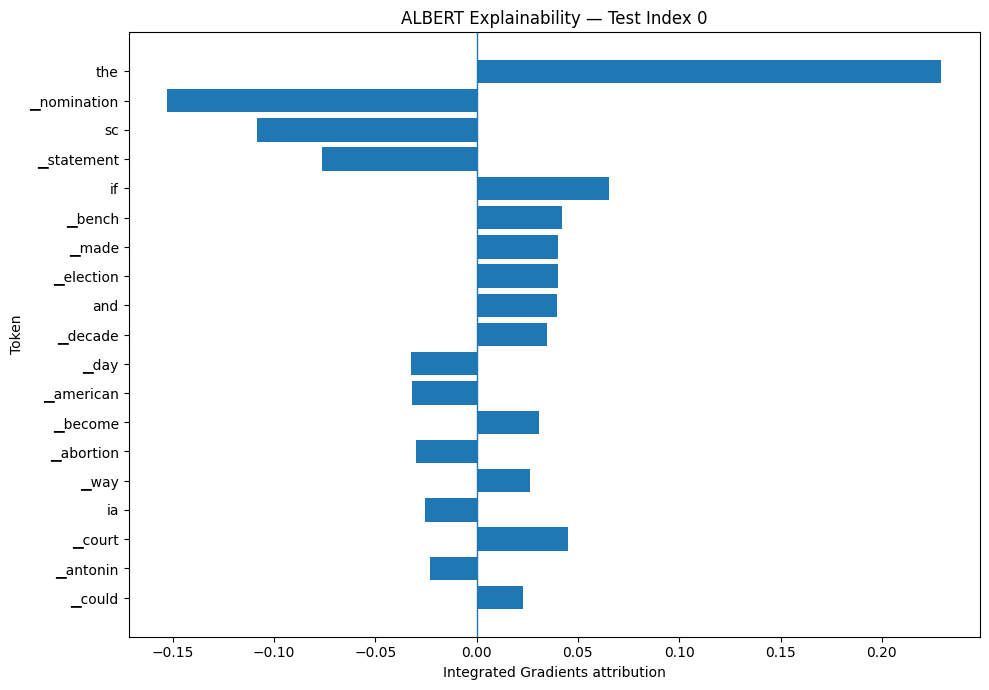

Saved: /content/ALBERT_explainability.csv

Interpretation:
  Positive attribution -> pushes prediction toward FAKE
  Negative attribution -> pushes prediction toward REAL


In [37]:
# ============================================
# 34. PLOT + SAVE EXPLANATION
# ============================================

top_tokens = (
    explanation_df
    .sort_values("abs_attribution", ascending=False)
    .head(20)
    .sort_values("abs_attribution")
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_tokens["token"],
    top_tokens["attribution"]
)
plt.axvline(0, linewidth=1)
plt.xlabel("Integrated Gradients attribution")
plt.ylabel("Token")
plt.title(
    f"ALBERT Explainability — Test Index {EXPLAIN_INDEX}"
)
plt.tight_layout()
plt.show()

# Save the explanation for the report/paper.
explanation_df.to_csv(
    "/content/ALBERT_explainability.csv",
    index=False
)

print("Saved: /content/ALBERT_explainability.csv")
print("\nInterpretation:")
print("  Positive attribution -> pushes prediction toward FAKE")
print("  Negative attribution -> pushes prediction toward REAL")

In [38]:
# ============================================
# GET 15 TEST SAMPLES
# ============================================

N_SAMPLES = 15

sample_ids = []
sample_masks = []
sample_labels = []

collected = 0

for input_ids, attention_mask, labels in test_loader:

    batch_size = input_ids.size(0)

    for i in range(batch_size):

        sample_ids.append(input_ids[i])
        sample_masks.append(attention_mask[i])
        sample_labels.append(labels[i])

        collected += 1

        if collected >= N_SAMPLES:
            break

    if collected >= N_SAMPLES:
        break

sample_ids = torch.stack(sample_ids).to(device)
sample_masks = torch.stack(sample_masks).to(device)
sample_labels = torch.stack(sample_labels).to(device)

print("Samples collected:", len(sample_labels))
print("Input shape:", sample_ids.shape)
print("Labels:", sample_labels.cpu().tolist())

Samples collected: 15
Input shape: torch.Size([15, 200])
Labels: [1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]


In [39]:
# ============================================
# RUN INTEGRATED GRADIENTS ON 15 ARTICLES
# ============================================

all_explanations = []
summary = []

special_tokens = set(
    x for x in [
        tokenizer.pad_token_id,
        tokenizer.cls_token_id,
        tokenizer.sep_token_id,
        tokenizer.unk_token_id
    ]
    if x is not None
)

print("=" * 80)
print("STARTING ALBERT EXPLAINABILITY")
print("=" * 80)

for sample_idx in range(N_SAMPLES):

    ids = sample_ids[sample_idx:sample_idx + 1]
    mask = sample_masks[sample_idx:sample_idx + 1]
    true_label = int(sample_labels[sample_idx].item())

    # PAD baseline
    baseline = torch.full_like(
        ids,
        fill_value=tokenizer.pad_token_id
    )

    # Integrated Gradients
    attributions, delta = lig.attribute(
        inputs=ids,
        baselines=baseline,
        additional_forward_args=(mask,),
        n_steps=16,
        return_convergence_delta=True
    )

    # One importance score per token
    token_scores = (
        attributions
        .sum(dim=-1)
        .squeeze(0)
        .detach()
        .cpu()
        .numpy()
    )

    token_ids = (
        ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    tokens = tokenizer.convert_ids_to_tokens(
        token_ids
    )

    # Prediction
    with torch.no_grad():

        logits = model_albert(
            input_ids=ids,
            attention_mask=mask
        ).logits

        probabilities = torch.softmax(
            logits,
            dim=-1
        )[0]

        predicted_label = int(
            torch.argmax(probabilities).item()
        )

        fake_probability = float(
            probabilities[1].item()
        )

    # Store token explanations
    valid_tokens = []

    for token, token_id, score in zip(
        tokens,
        token_ids,
        token_scores
    ):

        if token_id in special_tokens:
            continue

        valid_tokens.append({
            "sample": sample_idx,
            "token": token,
            "token_id": token_id,
            "attribution": float(score),
            "absolute_attribution": abs(float(score))
        })

    # Top 5 tokens pushing toward FAKE
    top_fake = sorted(
        valid_tokens,
        key=lambda x: x["attribution"],
        reverse=True
    )[:5]

    # Top 5 tokens pushing toward REAL
    top_real = sorted(
        valid_tokens,
        key=lambda x: x["attribution"]
    )[:5]

    all_explanations.extend(
        valid_tokens
    )

    summary.append({
        "sample": sample_idx,
        "actual": true_label,
        "predicted": predicted_label,
        "fake_probability": fake_probability,
        "convergence_delta": float(delta[0]),
        "top_fake_tokens": ", ".join(
            x["token"] for x in top_fake
        ),
        "top_real_tokens": ", ".join(
            x["token"] for x in top_real
        )
    })

    print(
        f"\nSample {sample_idx + 1}/{N_SAMPLES}"
    )

    print(
        f"Actual={true_label} | "
        f"Predicted={predicted_label} | "
        f"Fake probability={fake_probability:.4f}"
    )

    print(
        "Top FAKE:",
        [x["token"] for x in top_fake]
    )

    print(
        "Top REAL:",
        [x["token"] for x in top_real]
    )

    print(
        "Convergence delta:",
        round(float(delta[0]), 6)
    )

print("\n" + "=" * 80)
print("EXPLAINABILITY FINISHED")
print("=" * 80)

STARTING ALBERT EXPLAINABILITY

Sample 1/15
Actual=1 | Predicted=1 | Fake probability=0.9999
Top FAKE: ['the', '▁bench', '▁court', '▁decade', '▁made']
Top REAL: ['▁nomination', 'sc', '▁statement', '▁day', '▁election']
Convergence delta: -3.749505

Sample 2/15
Actual=0 | Predicted=0 | Fake probability=0.0000
Top FAKE: ['▁', '▁checkpoint', '▁similar', '▁cuban', '▁bre']
Top REAL: ['▁said', '▁thereafter', '▁process', 'ers', '▁policy']
Convergence delta: -82.38443

Sample 3/15
Actual=0 | Predicted=0 | Fake probability=0.0000
Top FAKE: ['▁senate', '▁vote', '▁u', '▁whether', '▁mcconnell']
Top REAL: ['▁reuters', '▁hour', '▁said', '▁healthcare', '▁within']
Convergence delta: 5.548641

Sample 4/15
Actual=1 | Predicted=1 | Fake probability=0.9996
Top FAKE: ['▁comment', '▁mind', '▁however', '▁experiencing', '▁loving']
Top REAL: ['▁therapy', '▁explains', '▁emotion', '▁body', '▁spiritual']
Convergence delta: -1.304638

Sample 5/15
Actual=0 | Predicted=0 | Fake probability=0.0000
Top FAKE: ['▁october

In [40]:
# ============================================
# SUMMARY OF ALL 15 EXPLANATIONS
# ============================================

summary_df = pd.DataFrame(summary)

display(summary_df)

print("\nCorrect predictions:",
      (summary_df["actual"] == summary_df["predicted"]).sum(),
      "/",
      len(summary_df))

print(
    "Average convergence delta:",
    summary_df["convergence_delta"].mean()
)

summary_df.to_csv(
    "/content/ALBERT_explainability_15_summary.csv",
    index=False
)

pd.DataFrame(all_explanations).to_csv(
    "/content/ALBERT_explainability_15_tokens.csv",
    index=False
)

print("\nSaved:")
print("/content/ALBERT_explainability_15_summary.csv")
print("/content/ALBERT_explainability_15_tokens.csv")

,sample,actual,predicted,fake_probability,convergence_delta,top_fake_tokens,top_real_tokens
0,0,1,1,0.999921,-3.749505,"the, ▁bench, ▁court, ▁decade, ▁made","▁nomination, sc, ▁statement, ▁day, ▁election"
1,1,0,0,0.000006,-82.384430,"▁, ▁checkpoint, ▁similar, ▁cuban, ▁bre","▁said, ▁thereafter, ▁process, ers, ▁policy"
2,2,0,0,0.000005,5.548641,"▁senate, ▁vote, ▁u, ▁whether, ▁mcconnell","▁reuters, ▁hour, ▁said, ▁healthcare, ▁within"
3,3,1,1,0.999619,-1.304638,"▁comment, ▁mind, ▁however, ▁experiencing, ▁loving","▁therapy, ▁explains, ▁emotion, ▁body, ▁spiritual"
4,4,0,0,0.000005,3.372712,"▁october, ▁snap, ▁inc, ▁hired, ▁percent","▁york, ▁time, ▁new, ▁thursday, ▁snap"
5,5,0,0,0.000006,4.767094,"▁carolina, ▁made, ▁carolina, ▁south, ▁rural","▁reuters, ▁carolina, ▁many, ▁mind, dom"
6,6,0,0,0.000005,5.976713,"▁reuters, n, ▁democracy, ▁go, ▁p","▁athens, ▁emmanuel, ▁athens, ▁hill, ny"
7,7,0,0,0.000008,-76.766113,"▁it, ▁, ▁rubi, ▁marco, ▁place","▁said, ▁pm, ▁seven, ▁thursday, car"
8,8,0,0,0.000009,-9.239535,"▁york, ▁tune, ▁pir, ▁saw, ▁urged","▁twitter, ▁sunday, ▁follow, er, ▁said"
9,9,0,0,0.000004,5.953983,"▁president, ▁congressional, ▁plan, ▁unveiled, ...","▁reuters, ▁washington, ▁trump, ▁donald, post"



Correct predictions: 15 / 15
Average convergence delta: -9.414723936716715

Saved:
/content/ALBERT_explainability_15_summary.csv
/content/ALBERT_explainability_15_tokens.csv


In [42]:
# ============================================================
# ALBERT INTEGRATED GRADIENTS - 50 ARTICLE BENCHMARK
# ============================================================

import time
import numpy as np
import pandas as pd
import torch

N_BENCHMARK = 50
N_STEPS = 16

# ------------------------------------------------------------
# Make sure model is in evaluation mode
# ------------------------------------------------------------

model_albert.eval()

# ------------------------------------------------------------
# Get 50 samples from the existing test_loader
# ------------------------------------------------------------

bench_ids = []
bench_masks = []
bench_labels = []

collected = 0

for input_ids, attention_mask, labels in test_loader:

    for i in range(input_ids.size(0)):

        bench_ids.append(input_ids[i])
        bench_masks.append(attention_mask[i])
        bench_labels.append(labels[i])

        collected += 1

        if collected >= N_BENCHMARK:
            break

    if collected >= N_BENCHMARK:
        break


bench_ids = torch.stack(bench_ids).to(device)
bench_masks = torch.stack(bench_masks).to(device)
bench_labels = torch.stack(bench_labels).to(device)

print("Benchmark samples:", len(bench_labels))
print("Input shape:", tuple(bench_ids.shape))
print("IG steps:", N_STEPS)

# ------------------------------------------------------------
# Warm-up one sample
# ------------------------------------------------------------

warmup_ids = bench_ids[0:1]
warmup_mask = bench_masks[0:1]

warmup_baseline = torch.full_like(
    warmup_ids,
    fill_value=tokenizer.pad_token_id
)

_ = lig.attribute(
    inputs=warmup_ids,
    baselines=warmup_baseline,
    additional_forward_args=(warmup_mask,),
    n_steps=N_STEPS,
    internal_batch_size=4
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

# ------------------------------------------------------------
# BENCHMARK
# ------------------------------------------------------------

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.perf_counter()

convergence_deltas = []

for i in range(N_BENCHMARK):

    ids = bench_ids[i:i+1]
    mask = bench_masks[i:i+1]

    baseline = torch.full_like(
        ids,
        fill_value=tokenizer.pad_token_id
    )

    attributions, delta = lig.attribute(
        inputs=ids,
        baselines=baseline,
        additional_forward_args=(mask,),
        n_steps=N_STEPS,
        internal_batch_size=4,
        return_convergence_delta=True
    )

    convergence_deltas.append(
        float(delta[0].detach().cpu())
    )

    if (i + 1) % 10 == 0:
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time

        print(
            f"{i+1}/{N_BENCHMARK} completed | "
            f"Elapsed: {elapsed:.2f} sec"
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()

total_seconds = time.perf_counter() - start_time

# ------------------------------------------------------------
# TIMING
# ------------------------------------------------------------

seconds_per_article = total_seconds / N_BENCHMARK

minutes_per_article = seconds_per_article / 60

print("\n" + "=" * 70)
print("BENCHMARK COMPLETE")
print("=" * 70)

print(f"Articles explained     : {N_BENCHMARK}")
print(f"Total time             : {total_seconds:.2f} seconds")
print(f"Time per article       : {seconds_per_article:.2f} seconds")
print(f"Time per article       : {minutes_per_article:.3f} minutes")

print(
    f"Mean convergence delta : "
    f"{np.mean(convergence_deltas):.6f}"
)

Benchmark samples: 50
Input shape: (50, 200)
IG steps: 16
10/50 completed | Elapsed: 7.76 sec
20/50 completed | Elapsed: 14.75 sec
30/50 completed | Elapsed: 21.48 sec
40/50 completed | Elapsed: 29.19 sec
50/50 completed | Elapsed: 36.01 sec

BENCHMARK COMPLETE
Articles explained     : 50
Total time             : 36.01 seconds
Time per article       : 0.72 seconds
Time per article       : 0.012 minutes
Mean convergence delta : -2.949108


In [43]:
# ============================================================
# RUNTIME EXTRAPOLATION
# ============================================================

FULL_TEST_SIZE = len(test_loader.dataset)

benchmarks = {
    "50 articles": 50,
    "200 articles": 200,
    "500 articles": 500,
    "Full test set": FULL_TEST_SIZE
}

rows = []

for name, count in benchmarks.items():

    estimated_seconds = (
        seconds_per_article * count
    )

    estimated_minutes = estimated_seconds / 60
    estimated_hours = estimated_minutes / 60

    rows.append({
        "Dataset": name,
        "Articles": count,
        "Estimated seconds": round(
            estimated_seconds, 2
        ),
        "Estimated minutes": round(
            estimated_minutes, 2
        ),
        "Estimated hours": round(
            estimated_hours, 2
        )
    })

runtime_df = pd.DataFrame(rows)

display(runtime_df)

,Dataset,Articles,Estimated seconds,Estimated minutes,Estimated hours
0,50 articles,50,36.01,0.60,0.01
1,200 articles,200,144.03,2.40,0.04
2,500 articles,500,360.07,6.00,0.10
3,Full test set,12625,9091.81,151.53,2.53


In [44]:
# ============================================================
# SIMPLE SUMMARY
# ============================================================

print("==============================================")
print("INTEGRATED GRADIENTS RUNTIME ESTIMATE")
print("==============================================")

print(
    f"Measured on 50 articles: "
    f"{total_seconds:.2f} seconds"
)

print(
    f"Average: "
    f"{seconds_per_article:.2f} seconds/article"
)

for count in [200, 500, FULL_TEST_SIZE]:

    estimated_hours = (
        seconds_per_article * count
    ) / 3600

    print(
        f"{count:,} articles -> "
        f"{estimated_hours:.2f} hours"
    )

INTEGRATED GRADIENTS RUNTIME ESTIMATE
Measured on 50 articles: 36.01 seconds
Average: 0.72 seconds/article
200 articles -> 0.04 hours
500 articles -> 0.10 hours
12,625 articles -> 2.53 hours


In [45]:
# ============================================================
# ALBERT INTEGRATED GRADIENTS - 500 ARTICLE RUN
# WITH PROGRESS BAR + ETA
# ============================================================

from tqdm.auto import tqdm
import time
import torch
import pandas as pd
import numpy as np

N_SAMPLES = 500
N_STEPS = 16

model_albert.eval()

# ------------------------------------------------------------
# Get 500 samples from the existing test_loader
# ------------------------------------------------------------

sample_ids = []
sample_masks = []
sample_labels = []

collected = 0

for input_ids, attention_mask, labels in test_loader:

    for i in range(input_ids.size(0)):

        sample_ids.append(input_ids[i])
        sample_masks.append(attention_mask[i])
        sample_labels.append(labels[i])

        collected += 1

        if collected >= N_SAMPLES:
            break

    if collected >= N_SAMPLES:
        break

sample_ids = torch.stack(sample_ids).to(device)
sample_masks = torch.stack(sample_masks).to(device)
sample_labels = torch.stack(sample_labels).to(device)

print("Samples collected:", len(sample_labels))
print("Input shape:", tuple(sample_ids.shape))

# ------------------------------------------------------------
# Run Integrated Gradients
# ------------------------------------------------------------

all_explanations = []
summary = []

special_tokens = set(
    x for x in [
        tokenizer.pad_token_id,
        tokenizer.cls_token_id,
        tokenizer.sep_token_id,
        tokenizer.unk_token_id
    ]
    if x is not None
)

start_time = time.perf_counter()

progress_bar = tqdm(
    range(N_SAMPLES),
    total=N_SAMPLES,
    desc="Integrated Gradients",
    unit="article",
    dynamic_ncols=True
)

for sample_idx in progress_bar:

    ids = sample_ids[sample_idx:sample_idx + 1]
    mask = sample_masks[sample_idx:sample_idx + 1]

    true_label = int(
        sample_labels[sample_idx].item()
    )

    # Baseline = padding tokens
    baseline = torch.full_like(
        ids,
        fill_value=tokenizer.pad_token_id
    )

    # --------------------------------------------------------
    # Integrated Gradients
    # --------------------------------------------------------

    attributions, delta = lig.attribute(
        inputs=ids,
        baselines=baseline,
        additional_forward_args=(mask,),
        n_steps=N_STEPS,
        internal_batch_size=4,
        return_convergence_delta=True
    )

    # One attribution score per token
    token_scores = (
        attributions
        .sum(dim=-1)
        .squeeze(0)
        .detach()
        .cpu()
        .numpy()
    )

    token_ids = (
        ids.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    tokens = tokenizer.convert_ids_to_tokens(
        token_ids
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    with torch.no_grad():

        logits = model_albert(
            input_ids=ids,
            attention_mask=mask
        ).logits

        probabilities = torch.softmax(
            logits,
            dim=-1
        )[0]

        predicted_label = int(
            torch.argmax(probabilities).item()
        )

        fake_probability = float(
            probabilities[1].item()
        )

    # --------------------------------------------------------
    # Save token explanations
    # --------------------------------------------------------

    valid_tokens = []

    for token, token_id, score in zip(
        tokens,
        token_ids,
        token_scores
    ):

        if token_id in special_tokens:
            continue

        valid_tokens.append({
            "sample": sample_idx,
            "token": token,
            "token_id": token_id,
            "attribution": float(score),
            "absolute_attribution": abs(float(score))
        })

    # Top tokens
    top_fake = sorted(
        valid_tokens,
        key=lambda x: x["attribution"],
        reverse=True
    )[:5]

    top_real = sorted(
        valid_tokens,
        key=lambda x: x["attribution"]
    )[:5]

    all_explanations.extend(
        valid_tokens
    )

    summary.append({
        "sample": sample_idx,
        "actual": true_label,
        "predicted": predicted_label,
        "fake_probability": fake_probability,
        "convergence_delta": float(
            delta[0].detach().cpu()
        ),
        "top_fake_tokens": ", ".join(
            x["token"] for x in top_fake
        ),
        "top_real_tokens": ", ".join(
            x["token"] for x in top_real
        )
    })

    # --------------------------------------------------------
    # Update progress bar information
    # --------------------------------------------------------

    elapsed = time.perf_counter() - start_time

    avg_time = elapsed / (sample_idx + 1)

    remaining = avg_time * (
        N_SAMPLES - sample_idx - 1
    )

    progress_bar.set_postfix(
        elapsed=f"{elapsed:.1f}s",
        eta=f"{remaining:.1f}s",
        avg=f"{avg_time:.2f}s/article"
    )

# ------------------------------------------------------------
# Finished
# ------------------------------------------------------------

total_time = time.perf_counter() - start_time

print("\n" + "=" * 70)
print("500-ARTICLE EXPLAINABILITY COMPLETE")
print("=" * 70)

print(
    f"Total time: {total_time:.2f} seconds"
)

print(
    f"Average: {total_time / N_SAMPLES:.2f} seconds/article"
)

print(
    f"Estimated 500-article runtime: "
    f"{total_time / 60:.2f} minutes"
)

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary)

explanations_df = pd.DataFrame(
    all_explanations
)

summary_df.to_csv(
    "/content/ALBERT_500_explainability_summary.csv",
    index=False
)

explanations_df.to_csv(
    "/content/ALBERT_500_explainability_tokens.csv",
    index=False
)

print("\nSaved:")
print("/content/ALBERT_500_explainability_summary.csv")
print("/content/ALBERT_500_explainability_tokens.csv")

display(summary_df.head(10))

Samples collected: 500
Input shape: (500, 200)


Integrated Gradients:   0%|          | 0/500 [00:00<?, ?article/s]


500-ARTICLE EXPLAINABILITY COMPLETE
Total time: 282.99 seconds
Average: 0.57 seconds/article
Estimated 500-article runtime: 4.72 minutes

Saved:
/content/ALBERT_500_explainability_summary.csv
/content/ALBERT_500_explainability_tokens.csv


,sample,actual,predicted,fake_probability,convergence_delta,top_fake_tokens,top_real_tokens
0,0,1,1,0.999921,-3.749503,"the, ▁bench, ▁court, ▁decade, ▁made","▁nomination, sc, ▁statement, ▁day, ▁election"
1,1,0,0,0.000006,-82.384789,"▁, ▁checkpoint, ▁similar, ▁cuban, ▁bre","▁said, ▁thereafter, ▁process, ers, ▁policy"
2,2,0,0,0.000005,5.548638,"▁senate, ▁vote, ▁u, ▁whether, ▁mcconnell","▁reuters, ▁hour, ▁said, ▁healthcare, ▁within"
3,3,1,1,0.999619,-1.304635,"▁comment, ▁mind, ▁however, ▁experiencing, ▁loving","▁therapy, ▁explains, ▁emotion, ▁body, ▁spiritual"
4,4,0,0,0.000005,3.372710,"▁october, ▁snap, ▁inc, ▁hired, ▁percent","▁york, ▁time, ▁new, ▁thursday, ▁snap"
5,5,0,0,0.000006,4.767098,"▁carolina, ▁made, ▁carolina, ▁south, ▁rural","▁reuters, ▁carolina, ▁many, ▁mind, dom"
6,6,0,0,0.000005,5.976713,"▁reuters, n, ▁democracy, ▁go, ▁p","▁athens, ▁emmanuel, ▁athens, ▁hill, ny"
7,7,0,0,0.000008,-76.771683,"▁it, ▁, ▁rubi, ▁marco, ▁place","▁said, ▁pm, ▁seven, ▁thursday, car"
8,8,0,0,0.000009,-9.239071,"▁york, ▁tune, ▁pir, ▁saw, ▁urged","▁twitter, ▁sunday, ▁follow, er, ▁said"
9,9,0,0,0.000004,5.953980,"▁president, ▁congressional, ▁plan, ▁unveiled, ...","▁reuters, ▁washington, ▁trump, ▁donald, post"
